In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load dataset
data = pd.read_csv("smart_meter_data.csv")

# 1️⃣ Parse timestamp column and sort chronologically
data['Timestamp'] = pd.to_datetime(data['Timestamp'])
data = data.sort_values('Timestamp')

# 2️⃣ Keep only normal (non-anomalous) records
data = data[data['Anomaly_Label'] == 'Normal']

# 3️⃣ Drop the anomaly column (not needed for forecasting)
data = data.drop(columns=['Anomaly_Label'])

# 4️⃣ Set Timestamp as index
data.set_index('Timestamp', inplace=True)

# 5️⃣ Train-test split (80% train, 20% test, sequentially)
split_index = int(len(data) * 0.8)
train = data.iloc[:split_index]
test = data.iloc[split_index:]

print("✅ Data prepared successfully!")
print("Training shape:", train.shape)
print("Testing shape:", test.shape)
print("\nColumns available:", list(data.columns))
print("\nTraining data preview:")
print(train.head())


✅ Data prepared successfully!
Training shape: (3800, 5)
Testing shape: (950, 5)

Columns available: ['Electricity_Consumed', 'Temperature', 'Humidity', 'Wind_Speed', 'Avg_Past_Consumption']

Training data preview:
                     Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
Timestamp                                                                      
2024-01-01 00:00:00              0.457786     0.469524  0.396368    0.445441   
2024-01-01 00:30:00              0.351956     0.465545  0.451184    0.458729   
2024-01-01 01:00:00              0.482948     0.285415  0.408289    0.470360   
2024-01-01 01:30:00              0.628838     0.482095  0.512308    0.576241   
2024-01-01 02:00:00              0.335974     0.624741  0.672021    0.373004   

                     Avg_Past_Consumption  
Timestamp                                  
2024-01-01 00:00:00              0.692057  
2024-01-01 00:30:00              0.539874  
2024-01-01 01:00:00              0.614724  
2024-

In [2]:
!pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np

# 1️⃣ Define how many past timesteps to use (e.g., 24 = last 12 hours if each step = 30 min)
n_steps = 24

# 2️⃣ Separate features (X) and target (y)
feature_cols = ['Temperature', 'Humidity', 'Wind_Speed', 'Avg_Past_Consumption']
target_col = 'Electricity_Consumed'

def create_sequences(data, n_steps):
    X, y = [], []
    for i in range(n_steps, len(data)):
        seq_x = data[feature_cols].iloc[i-n_steps:i].values
        seq_y = data[target_col].iloc[i]
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

# 3️⃣ Create sequences for train and test sets
X_train, y_train = create_sequences(train, n_steps)
X_test, y_test = create_sequences(test, n_steps)

print("✅ Sequences created successfully!")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


✅ Sequences created successfully!
X_train shape: (3776, 24, 4)
y_train shape: (3776,)
X_test shape: (926, 24, 4)
y_test shape: (926,)


In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1️⃣ Define the model
model = Sequential([
    LSTM(64, activation='tanh', return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, activation='tanh'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)  # Output layer for regression (predicting consumption)
])

# 2️⃣ Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 3️⃣ Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=25,
    batch_size=32,
    verbose=1
)

# 4️⃣ Evaluate
loss, mae = model.evaluate(X_test, y_test)
print(f"✅ Model trained successfully! Test MAE: {mae:.4f}")


C:\Program Files\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - loss: 0.0284 - mae: 0.1362 - val_loss: 0.0237 - val_mae: 0.1260
Epoch 2/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0251 - mae: 0.1273 - val_loss: 0.0229 - val_mae: 0.1239
Epoch 3/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0245 - mae: 0.1268 - val_loss: 0.0229 - val_mae: 0.1237
Epoch 4/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0243 - mae: 0.1264 - val_loss: 0.0225 - val_mae: 0.1218
Epoch 5/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: 0.0241 - mae: 0.1263 - val_loss: 0.0222 - val_mae: 0.1216
Epoch 6/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0237 - mae: 0.1250 - val_loss: 0.0224 - val_mae: 0.1221
Epoch 7/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0240 - mae: 0.1257 - val_loss: 0.0222 - val_mae: 0.1215
Epoch 8/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0237 - mae: 0.1250 - val_loss: 0.0222 - val_mae: 0.1215
Epoch 9/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step
✅ Forecasting metrics:
RMSE: 0.1491
MAE: 0.1215
MAPE: 65.00%


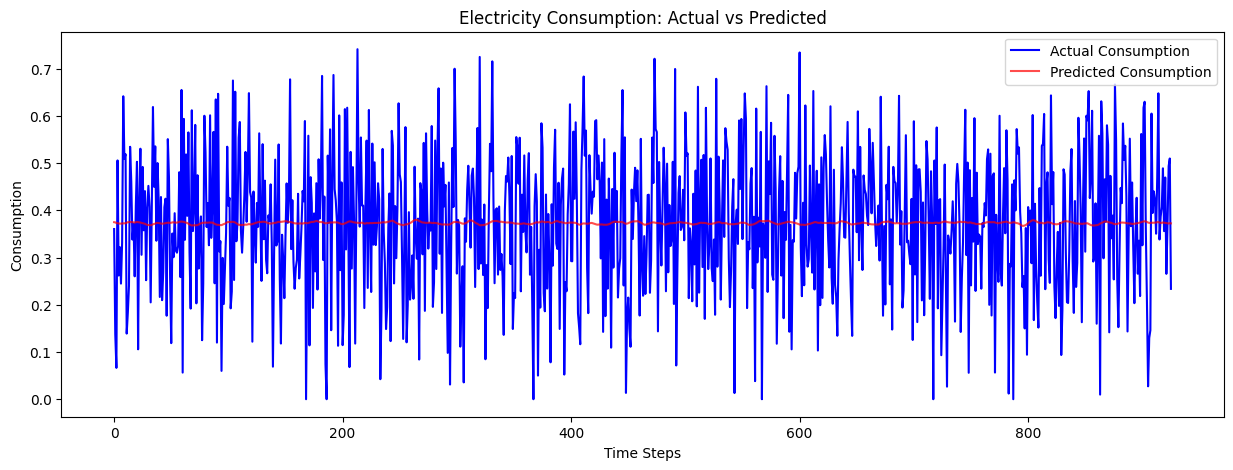

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1️⃣ Make predictions
y_pred = model.predict(X_test)
y_pred_flat = y_pred.reshape(-1)  # Flatten for convenience

# 2️⃣ Compute evaluation metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred_flat))
mae = mean_absolute_error(y_test, y_pred_flat)

# Fix MAPE: avoid division by zero
non_zero_idx = y_test != 0
y_test_non_zero = y_test[non_zero_idx]
y_pred_non_zero = y_pred_flat[non_zero_idx]
mape = np.mean(np.abs((y_test_non_zero - y_pred_non_zero) / y_test_non_zero)) * 100

print(f"✅ Forecasting metrics:")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.2f}%")

# 3️⃣ Plot actual vs predicted
plt.figure(figsize=(15,5))
plt.plot(y_test, label='Actual Consumption', color='blue')
plt.plot(y_pred_flat, label='Predicted Consumption', color='red', alpha=0.7)
plt.title('Electricity Consumption: Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Consumption')
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━

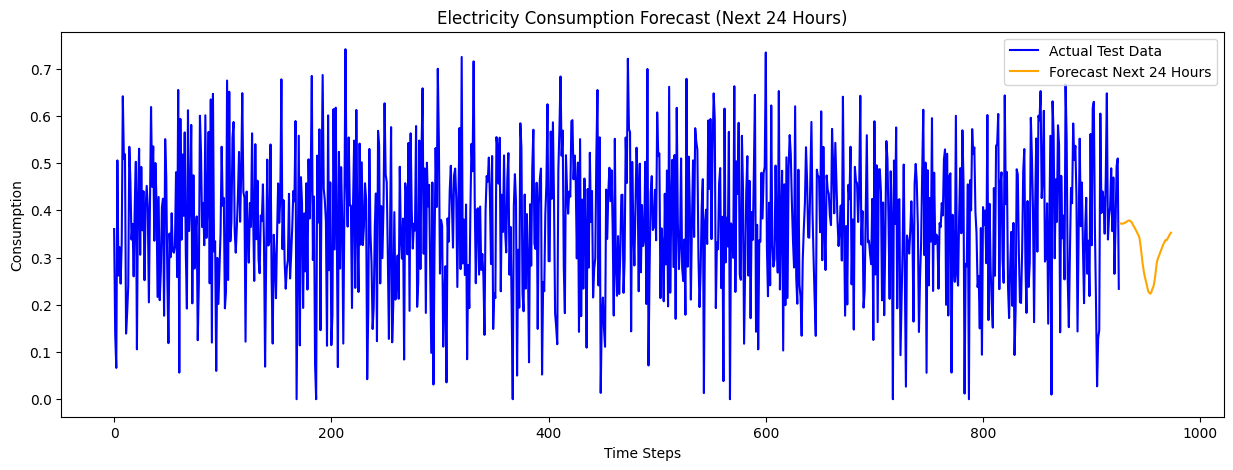

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ---- SETTINGS ----
future_steps = 48  # number of steps to forecast (e.g., next 24 hours if 30-min intervals)
n_steps = X_test.shape[1]  # sequence length used in LSTM
n_features = X_test.shape[2]  # number of features
feature_cols = ['Temperature','Humidity','Wind_Speed','Avg_Past_Consumption']  # adjust as per your data

# ---- START WITH LAST TEST SEQUENCE ----
current_seq = X_test[-1].copy()
forecast = []

# ---- RECURSIVE FORECAST LOOP ----
for _ in range(future_steps):
    # Predict next consumption
    next_pred = model.predict(current_seq.reshape(1, n_steps, n_features))[0,0]
    forecast.append(next_pred)
    
    # Prepare next input step
    new_step = current_seq[-1].copy()
    
    # Update Avg_Past_Consumption with predicted value
    new_step[-1] = next_pred
    
    # ---- OPTIONAL: update weather features ----
    # You can use actual future values if available,
    # or simulate small realistic variations
    new_step[0] += np.random.normal(0, 0.5)  # Temperature
    new_step[1] += np.random.normal(0, 0.5)  # Humidity
    new_step[2] += np.random.normal(0, 0.1)  # Wind_Speed
    
    # Append new step to sequence and remove oldest
    current_seq = np.vstack([current_seq[1:], new_step])

# Convert forecast to numpy array
forecast = np.array(forecast)

# ---- DENORMALIZE (if you used MinMaxScaler) ----
forecast_real = forecast
y_test_real = y_test


# ---- PLOT ----
plt.figure(figsize=(15,5))
plt.plot(range(len(y_test_real)), y_test_real, label='Actual Test Data', color='blue')
plt.plot(range(len(y_test_real), len(y_test_real)+future_steps), forecast_real, label='Forecast Next 24 Hours', color='orange')
plt.title('Electricity Consumption Forecast (Next 24 Hours)')
plt.xlabel('Time Steps')
plt.ylabel('Consumption')
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━

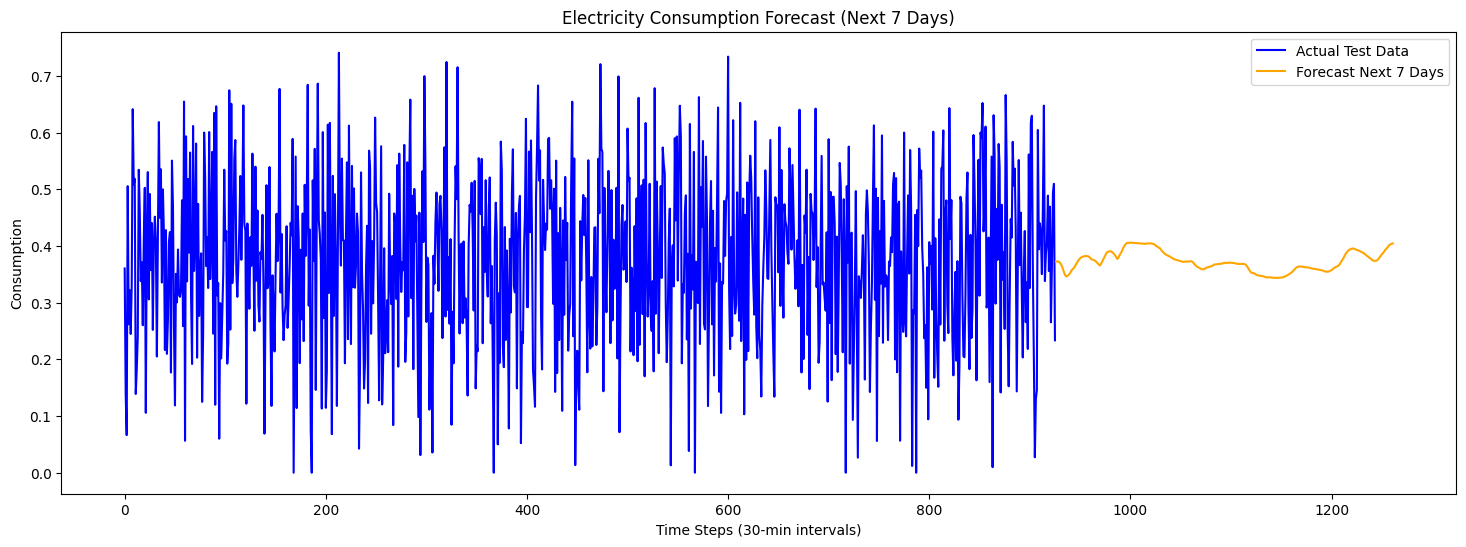

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ---- SETTINGS ----
steps_per_day = 48       # 30-min intervals
forecast_days = 7      # 2 months
future_steps = steps_per_day * forecast_days  # total steps to forecast

n_steps = X_test.shape[1]  # sequence length used by LSTM
n_features = X_test.shape[2]
feature_cols = ['Temperature','Humidity','Wind_Speed','Avg_Past_Consumption']

# ---- START WITH LAST SEQUENCE ----
# Use last n_steps from train + test if test is too small
if len(X_test) == 0:
    # Combine last n_steps from train
    current_seq = X_train[-1].copy()
else:
    current_seq = X_test[-1].copy()

forecast = []

# ---- RECURSIVE FORECAST LOOP ----
for step in range(future_steps):
    # Predict next consumption
    next_pred = model.predict(current_seq.reshape(1, n_steps, n_features))[0,0]
    forecast.append(next_pred)
    
    # Prepare next input step
    new_step = current_seq[-1].copy()
    
    # Update Avg_Past_Consumption
    new_step[-1] = next_pred
    
    # ---- SIMULATE WEATHER AND WEEKLY PATTERNS ----
    # Daily pattern: add sinusoidal variation for Temperature
    daily_factor = np.sin(2 * np.pi * (step % steps_per_day) / steps_per_day)
    weekly_factor = np.sin(2 * np.pi * (step % (steps_per_day*7)) / (steps_per_day*7))
    
    new_step[0] += 0.5 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Temperature
    new_step[1] += 0.3 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Humidity
    new_step[2] += 0.05 * daily_factor + np.random.normal(0, 0.1)                       # Wind Speed
    
    # Append new step and remove oldest
    current_seq = np.vstack([current_seq[1:], new_step])

forecast = np.array(forecast)

# ---- PLOT ----
plt.figure(figsize=(18,6))

# Plot available test data if exists
if len(X_test) > 0:
    plt.plot(range(len(y_test)), y_test, label='Actual Test Data', color='blue')

plt.plot(range(len(y_test), len(y_test)+future_steps), forecast, label=f'Forecast Next {forecast_days} Days', color='orange')

plt.title(f'Electricity Consumption Forecast (Next {forecast_days} Days)')
plt.xlabel('Time Steps (30-min intervals)')
plt.ylabel('Consumption')
plt.legend()
plt.show()


Forecasted day 1 / 60
Forecasted day 2 / 60
Forecasted day 3 / 60
Forecasted day 4 / 60
Forecasted day 5 / 60
Forecasted day 6 / 60
Forecasted day 7 / 60
Forecasted day 8 / 60
Forecasted day 9 / 60
Forecasted day 10 / 60
Forecasted day 11 / 60
Forecasted day 12 / 60
Forecasted day 13 / 60
Forecasted day 14 / 60
Forecasted day 15 / 60
Forecasted day 16 / 60
Forecasted day 17 / 60
Forecasted day 18 / 60
Forecasted day 19 / 60
Forecasted day 20 / 60
Forecasted day 21 / 60
Forecasted day 22 / 60
Forecasted day 23 / 60
Forecasted day 24 / 60
Forecasted day 25 / 60
Forecasted day 26 / 60
Forecasted day 27 / 60
Forecasted day 28 / 60
Forecasted day 29 / 60
Forecasted day 30 / 60
Forecasted day 31 / 60
Forecasted day 32 / 60
Forecasted day 33 / 60
Forecasted day 34 / 60
Forecasted day 35 / 60
Forecasted day 36 / 60
Forecasted day 37 / 60
Forecasted day 38 / 60
Forecasted day 39 / 60
Forecasted day 40 / 60
Forecasted day 41 / 60
Forecasted day 42 / 60
Forecasted day 43 / 60
Forecasted day 44 / 

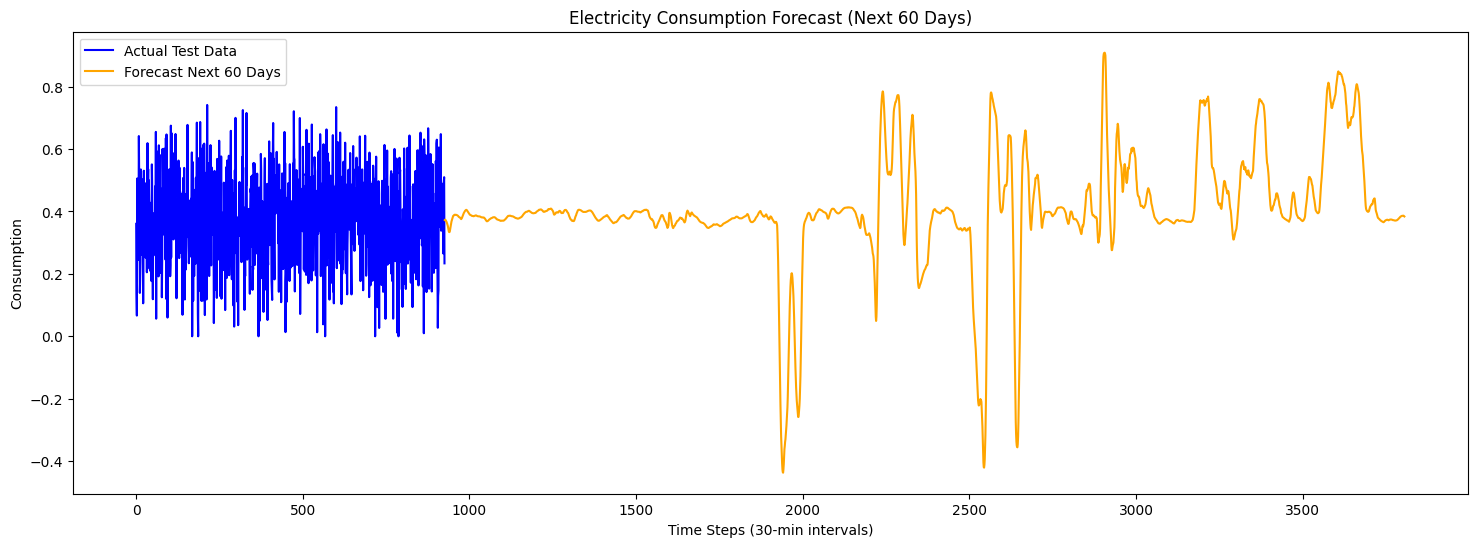

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ---- SETTINGS ----
steps_per_day = 48       # 30-min intervals
forecast_days = 60       # 2 months
future_steps = steps_per_day * forecast_days  # total steps to forecast

n_steps = X_test.shape[1] if len(X_test) > 0 else X_train.shape[1]  # sequence length
n_features = X_test.shape[2] if len(X_test) > 0 else X_train.shape[2]
feature_cols = ['Temperature','Humidity','Wind_Speed','Avg_Past_Consumption']

# ---- START WITH LAST SEQUENCE ----
if len(X_test) == 0:
    current_seq = X_train[-1].copy()
else:
    current_seq = X_test[-1].copy()

forecast = []

# ---- RECURSIVE FORECAST LOOP ----
for step in range(future_steps):
    # Predict next consumption (suppress verbose logs)
    next_pred = model.predict(current_seq.reshape(1, n_steps, n_features), verbose=0)[0,0]
    forecast.append(next_pred)
    
    # Prepare next input step
    new_step = current_seq[-1].copy()
    new_step[-1] = next_pred  # Update Avg_Past_Consumption

    # ---- SIMULATE WEATHER AND WEEKLY PATTERNS ----
    daily_factor = np.sin(2 * np.pi * (step % steps_per_day) / steps_per_day)
    weekly_factor = np.sin(2 * np.pi * (step % (steps_per_day*7)) / (steps_per_day*7))
    
    new_step[0] += 0.5 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Temperature
    new_step[1] += 0.3 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Humidity
    new_step[2] += 0.05 * daily_factor + np.random.normal(0, 0.1)                       # Wind Speed
    
    # Append new step and remove oldest
    current_seq = np.vstack([current_seq[1:], new_step])
    
    # ---- PROGRESS UPDATE ----
    if (step+1) % steps_per_day == 0:
        print(f"Forecasted day {(step+1)//steps_per_day} / {forecast_days}")

forecast = np.array(forecast)

# ---- PLOT ----
plt.figure(figsize=(18,6))

# Plot available test data if exists
if len(X_test) > 0:
    plt.plot(range(len(y_test)), y_test, label='Actual Test Data', color='blue')

plt.plot(range(len(y_test), len(y_test)+future_steps), forecast, label=f'Forecast Next {forecast_days} Days', color='orange')

plt.title(f'Electricity Consumption Forecast (Next {forecast_days} Days)')
plt.xlabel('Time Steps (30-min intervals)')
plt.ylabel('Consumption')
plt.legend()
plt.show()


Forecasted day 1 / 1


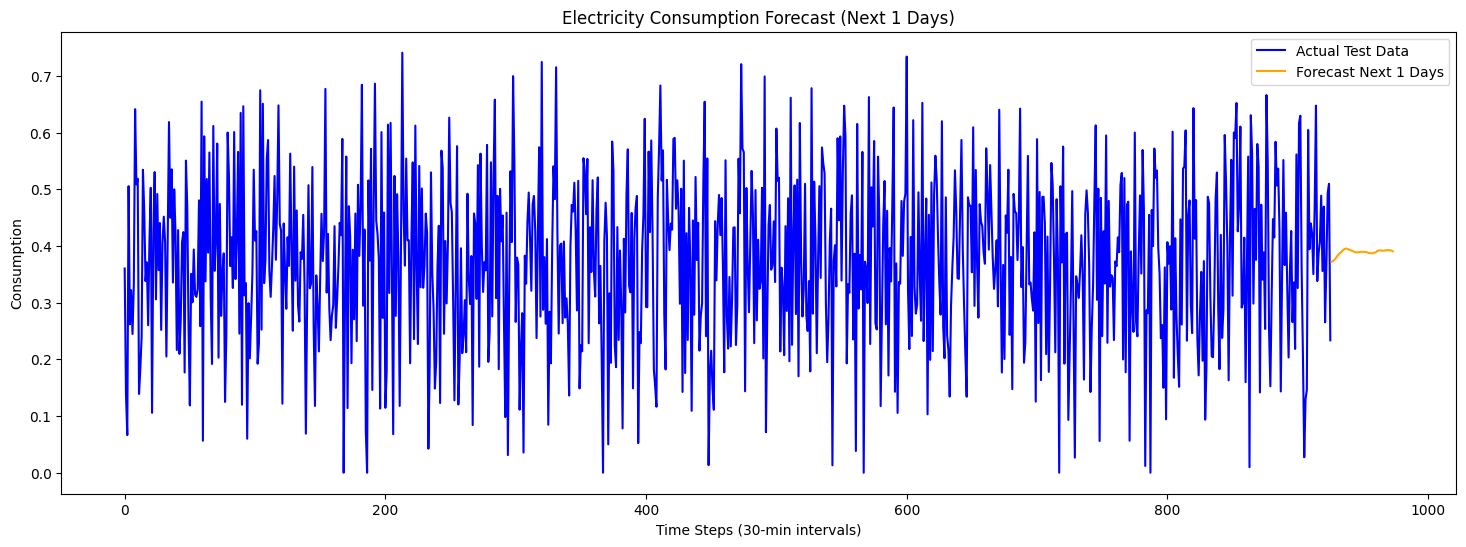

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ---- SETTINGS ----
steps_per_day = 48       # 30-min intervals
forecast_days = 1      
future_steps = steps_per_day * forecast_days  # total steps to forecast

n_steps = X_test.shape[1] if len(X_test) > 0 else X_train.shape[1]  # sequence length
n_features = X_test.shape[2] if len(X_test) > 0 else X_train.shape[2]
feature_cols = ['Temperature','Humidity','Wind_Speed','Avg_Past_Consumption']

# ---- START WITH LAST SEQUENCE ----
if len(X_test) == 0:
    current_seq = X_train[-1].copy()
else:
    current_seq = X_test[-1].copy()

forecast = []

# ---- RECURSIVE FORECAST LOOP ----
for step in range(future_steps):
    # Predict next consumption (suppress verbose logs)
    next_pred = model.predict(current_seq.reshape(1, n_steps, n_features), verbose=0)[0,0]
    forecast.append(next_pred)
    
    # Prepare next input step
    new_step = current_seq[-1].copy()
    new_step[-1] = next_pred  # Update Avg_Past_Consumption

    # ---- SIMULATE WEATHER AND WEEKLY PATTERNS ----
    daily_factor = np.sin(2 * np.pi * (step % steps_per_day) / steps_per_day)
    weekly_factor = np.sin(2 * np.pi * (step % (steps_per_day*7)) / (steps_per_day*7))
    
    new_step[0] += 0.5 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Temperature
    new_step[1] += 0.3 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Humidity
    new_step[2] += 0.05 * daily_factor + np.random.normal(0, 0.1)                       # Wind Speed
    
    # Append new step and remove oldest
    current_seq = np.vstack([current_seq[1:], new_step])
    
    # ---- PROGRESS UPDATE ----
    if (step+1) % steps_per_day == 0:
        print(f"Forecasted day {(step+1)//steps_per_day} / {forecast_days}")

forecast = np.array(forecast)

# ---- PLOT ----
plt.figure(figsize=(18,6))

# Plot available test data if exists
if len(X_test) > 0:
    plt.plot(range(len(y_test)), y_test, label='Actual Test Data', color='blue')

plt.plot(range(len(y_test), len(y_test)+future_steps), forecast, label=f'Forecast Next {forecast_days} Days', color='orange')

plt.title(f'Electricity Consumption Forecast (Next {forecast_days} Days)')
plt.xlabel('Time Steps (30-min intervals)')
plt.ylabel('Consumption')
plt.legend()
plt.show()


Forecasted day 1 / 7
Forecasted day 2 / 7
Forecasted day 3 / 7
Forecasted day 4 / 7
Forecasted day 5 / 7
Forecasted day 6 / 7
Forecasted day 7 / 7


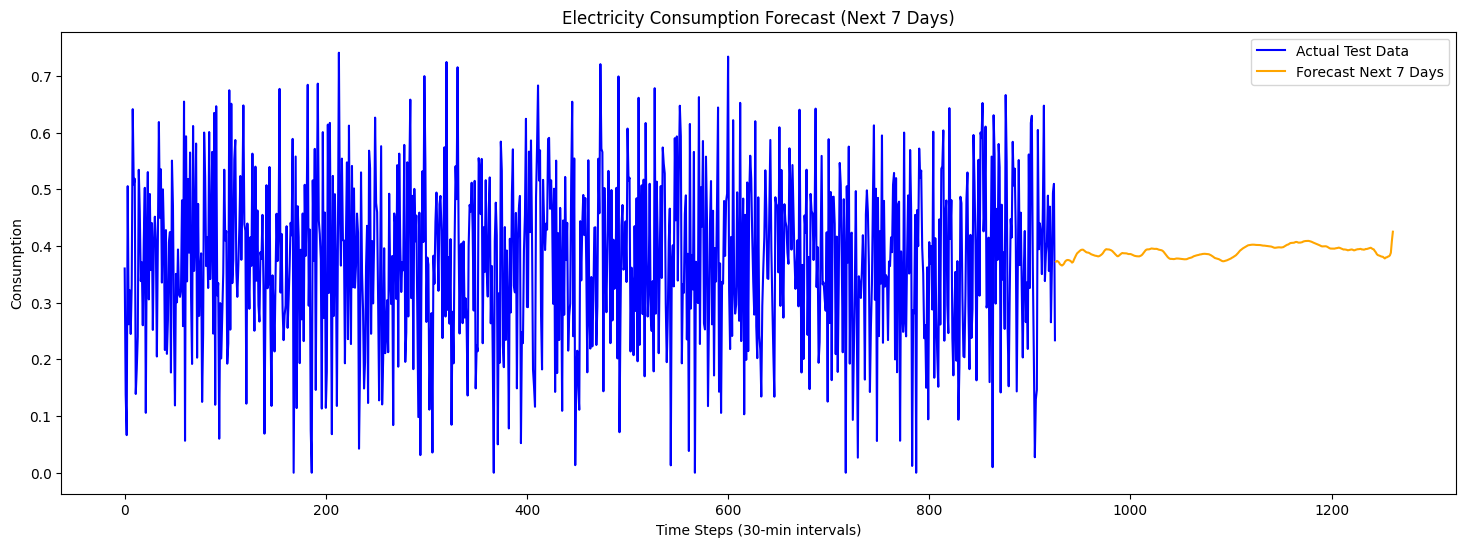

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ---- SETTINGS ----
steps_per_day = 48       # 30-min intervals
forecast_days = 7      # 2 months
future_steps = steps_per_day * forecast_days  # total steps to forecast

n_steps = X_test.shape[1] if len(X_test) > 0 else X_train.shape[1]  # sequence length
n_features = X_test.shape[2] if len(X_test) > 0 else X_train.shape[2]
feature_cols = ['Temperature','Humidity','Wind_Speed','Avg_Past_Consumption']

# ---- START WITH LAST SEQUENCE ----
if len(X_test) == 0:
    current_seq = X_train[-1].copy()
else:
    current_seq = X_test[-1].copy()

forecast = []

# ---- RECURSIVE FORECAST LOOP ----
for step in range(future_steps):
    # Predict next consumption (suppress verbose logs)
    next_pred = model.predict(current_seq.reshape(1, n_steps, n_features), verbose=0)[0,0]
    forecast.append(next_pred)
    
    # Prepare next input step
    new_step = current_seq[-1].copy()
    new_step[-1] = next_pred  # Update Avg_Past_Consumption

    # ---- SIMULATE WEATHER AND WEEKLY PATTERNS ----
    daily_factor = np.sin(2 * np.pi * (step % steps_per_day) / steps_per_day)
    weekly_factor = np.sin(2 * np.pi * (step % (steps_per_day*7)) / (steps_per_day*7))
    
    new_step[0] += 0.5 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Temperature
    new_step[1] += 0.3 * daily_factor + 0.2 * weekly_factor + np.random.normal(0, 0.5)  # Humidity
    new_step[2] += 0.05 * daily_factor + np.random.normal(0, 0.1)                       # Wind Speed
    
    # Append new step and remove oldest
    current_seq = np.vstack([current_seq[1:], new_step])
    
    # ---- PROGRESS UPDATE ----
    if (step+1) % steps_per_day == 0:
        print(f"Forecasted day {(step+1)//steps_per_day} / {forecast_days}")

forecast = np.array(forecast)

# ---- PLOT ----
plt.figure(figsize=(18,6))

# Plot available test data if exists
if len(X_test) > 0:
    plt.plot(range(len(y_test)), y_test, label='Actual Test Data', color='blue')

plt.plot(range(len(y_test), len(y_test)+future_steps), forecast, label=f'Forecast Next {forecast_days} Days', color='orange')

plt.title(f'Electricity Consumption Forecast (Next {forecast_days} Days)')
plt.xlabel('Time Steps (30-min intervals)')
plt.ylabel('Consumption')
plt.legend()
plt.show()
